In [ ]:
import numpy as np

## <span style='color: blue'>Zadanie 1: Wyznaczyć wskaźniki statystyczne ciągu liczb</span>
1. Min
2. Max
3. Q1, Q2, Q3
4. Wartości odstające

In [1]:
np.random.seed(32798)

tab = np.array([1, 3, 15,
16, 16, 19, 20, 20, 21, 22, 22, 25, 25, 25, 25, 30, 33, 33, 35, 35, 36, 40, 45, 46, 95])
tab = np.random.choice(tab, size=len(tab), replace=True)
tab

NameError: name 'np' is not defined

In [ ]:
# Wyznaczyć Min
Min = tab.min()
Min

np.int64(1)

In [ ]:
# Wyznaczyć Max
Max = tab.max()
Max

np.int64(95)

In [ ]:
# Wyznaczyć Q1
Q1 = np.quantile(tab, 0.25)
Q1

np.float64(19.0)

In [ ]:
# Wyznaczyć Mean
Mean = tab.mean()
Mean

np.float64(29.8)

In [ ]:
# Wyznaczyć Q3
Q3 = np.quantile(tab, 0.75)
Q3

np.float64(35.0)

In [ ]:
# Wyznaczyć przedział akceptowanych wartości:
# Dolna granica: a = Q1 -1.5* (Q3-Q1)
# Górna granica: b = Q3 +1.5 *(Q3 -Q1)

a = Q1 -1.5* (Q3-Q1)
b = Q3 +1.5 *(Q3 -Q1)
a
b

np.float64(59.0)

In [ ]:
# Funkcja do wyznaczenia wartości odstających
# def outliers ()

def outliers():
  return tab[(tab < a) | (tab > b)]

test = outliers()
test

array([95])

## <span style='color: blue'>Zadanie 2: Aproksymacja średniej i mediany</span>

In [ ]:
# Oszacowanie sredniej
avg = np.average(tab)
avg

np.float64(29.8)

In [ ]:
# Oszacowanie mediany
med = np.median(tab)
med

np.float64(25.0)

##  <span style='color: blue'>Zdanie 3: Analiza korelacji między poziomem tłuszczu i wiekiem</span>  

__Wiek__ __Poziom tłuszczu__

23 9.5

23 26.5

27 17.8

39 31.4

41 25.9

47 27.4

49 27.2

50 31.2

52 34.6

54 42.5

54 28.8

56 33.4

57 30.2

58 34.1

58 32.9

60 41.2

61 35.7

1. Wskaźniki statystyczne: średnia, median, odchylenie standardowe  *Wiek* i *Poziom tłuszczu*.
2. Współczynnik Pearsona.
3. Prosta regresyjna
4. Błąd kwadratowy


## <span style='color: blue'>Zadanie 3: Analiza korelacji</span>

In [ ]:
wiek_tluszcz = np.array ([[23, 9.5],
[23, 26.5],
[27, 17.8],
[39, 31.4],
[41, 25.9],
[47, 27.4],
[49, 27.2],
[50, 31.2],
[52, 34.6],
[54, 42.5],
[54, 28.8],
[56, 33.4],
[57, 30.2],
[58, 34.1],
[58, 32.9],
[60, 41.2],
[61, 35.7]])
print (wiek_tluszcz.shape)

(17, 2)


In [ ]:
# Wiek: Srednia, Mediana, StdDev
wiek = wiek_tluszcz[:,0]

wiek_avg = wiek.mean()
wiek_med = np.median(wiek)
wiek_std = wiek.std()

In [ ]:
#histogram Wieku
h = np.histogram(wiek)
h

(array([2, 1, 0, 0, 2, 0, 2, 2, 4, 4]),
 array([23. , 26.8, 30.6, 34.4, 38.2, 42. , 45.8, 49.6, 53.4, 57.2, 61. ]))

In [ ]:
# Tłuszcz: Średnia, Mediana, StdDev
tluszcz = wiek_tluszcz[:,1]
tluszcz_avg = tluszcz.mean()
tluszcz_med = np.median(tluszcz)
tluszcz_std = tluszcz.std()

In [ ]:
# Histogram Poziom Tłuszczu
h_t = np.histogram(tluszcz)
h_t

(array([1, 0, 1, 0, 1, 4, 3, 5, 0, 2]),
 array([ 9.5, 12.8, 16.1, 19.4, 22.7, 26. , 29.3, 32.6, 35.9, 39.2, 42.5]))

## Korelacja Pearsona

Pearson Wiek vs Tluszcz = [[1.         0.79522853]
 [0.79522853 1.        ]]


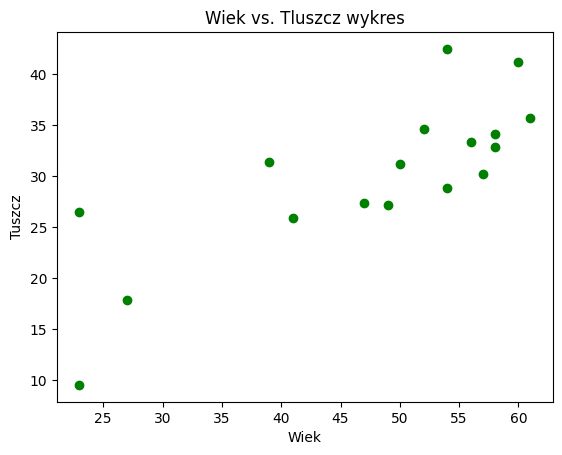

In [ ]:
# Współczynnik korelacji Pearsona
import matplotlib.pyplot as plt

plt.plot (wiek, tluszcz,"go")
plt.title ("Wiek vs. Tluszcz wykres")
plt.xlabel ("Wiek")
plt.ylabel ("Tuszcz")
plt.show
f_Pearson = np.corrcoef(wiek, tluszcz)
print ('Pearson Wiek vs Tluszcz =', f_Pearson)

## Linia regresyjna

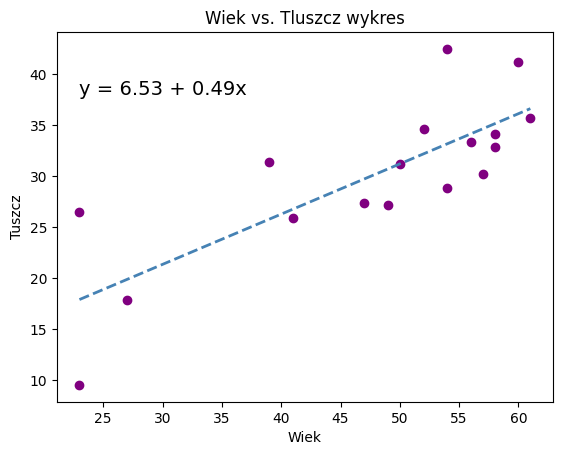

In [ ]:
import warnings
warnings.filterwarnings("ignore")

#find line of best fit
a, b = np.polyfit(wiek, tluszcz, 1)
tluszcz_pred = a*wiek+b

#add points to plot
#plt.scatter(wiek, tluszcz, color='purple')
plt.title ("Wiek vs. Tluszcz wykres")
plt.xlabel ("Wiek")
plt.ylabel ("Tuszcz")
plt.scatter(wiek, tluszcz, color='purple')
#add line of best fit to plot
plt.plot(wiek, tluszcz_pred, color='steelblue', linestyle='--', linewidth=2)

#add fitted regression equation to plot
plt.text(23, 38, 'y = ' + '{:.2f}'.format(b) + ' + {:.2f}'.format(a) + 'x', size=14)
plt.show()


## Błąd kwadratowy  (MSE)

In [ ]:
# Błąd kwadratowy
r = tluszcz - tluszcz_pred
MSE = np.mean(r**2)
MSE


np.float64(21.40244803194554)

## <span style='color: blue'>Zadanie 4: Odległość między wektorami</span>

In [ ]:
# Odległość Euklidesowa
# Podobieństwo cosinusowe
# Kąt
u = wiek_tluszcz[0]
v = wiek_tluszcz[3]

Odleglosc = np.sqrt(np.sum((u-v)** 2))
cos_pod = np.dot(u,v) / (np.linalg.norm(u) * np.linalg.norm(v))
kat = np.arccos(cos_pod)

## <span style='color: blue'>Zadanie 5: Klasyfikacja. kNN </span>

In [ ]:
trn_set = np.array([[15, 17],
                    [2, 19],
                    [16, 18],
                    [12, 15],
                    [15, 10]]
                  )
trn_label = np.array([[0],
                      [0],
                      [1],
                      [1],
                      [1]])
print(trn_set)
V_new = np.array([14, 16])
# Klasyfikacja 1-NN, Odległość Euklidesowa
Odleglosci = np.sqrt(np.sum((trn_set-V_new)** 2, axis=1))
idx = np.argmin(Odleglosci)
klasa = trn_label[idx]
print(Odleglosci)
print(idx)
print(klasa)

[[15 17]
 [ 2 19]
 [16 18]
 [12 15]
 [15 10]]
[ 1.41421356 12.36931688  2.82842712  2.23606798  6.08276253]
0
[0]


In [ ]:
# 1-NN, podobieństwo cosinusowe
mods= np.linalg.norm(trn_set, axis=1)
mod_new = np.linalg.norm(V_new)
cos_pod = np.dot(trn_set,V_new) / (mods * mod_new)
idx = np.argmax(cos_pod)
klasa = trn_label[idx, 0]
klasa


np.int64(0)

## <span style='color: blue'>Zadanie 6: Normalizacja </span>

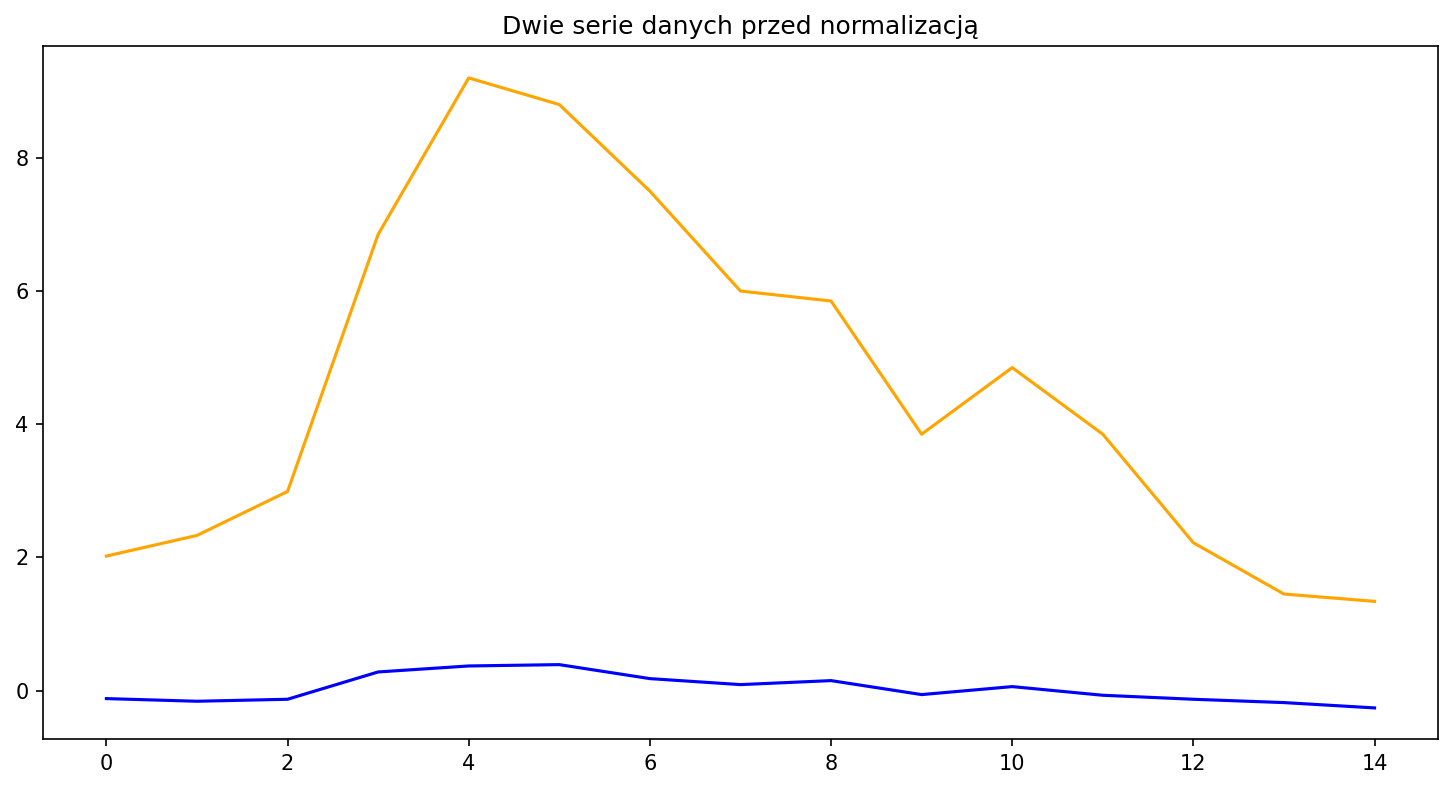

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

s1 = np.array([2.02, 2.33, 2.99, 6.85, 9.20, 8.80, 7.50, 6.00, 5.85, 3.85, 4.85, 3.85, 2.22, 1.45, 1.34])
s2 = np.array([-0.12,-0.16,-0.13, 0.28, 0.37, 0.39, 0.18, 0.09, 0.15,-0.06, 0.06,-0.07,-0.13,-0.18,-0.26])
# Wyświetlić 2 serie danych na jednym rysunku
plt.figure(figsize=(12, 6), dpi=150)

plt.plot(s1, color='orange')
plt.plot(s2, color='blue')
plt.title ("Dwie serie danych przed normalizacją")
plt.show()


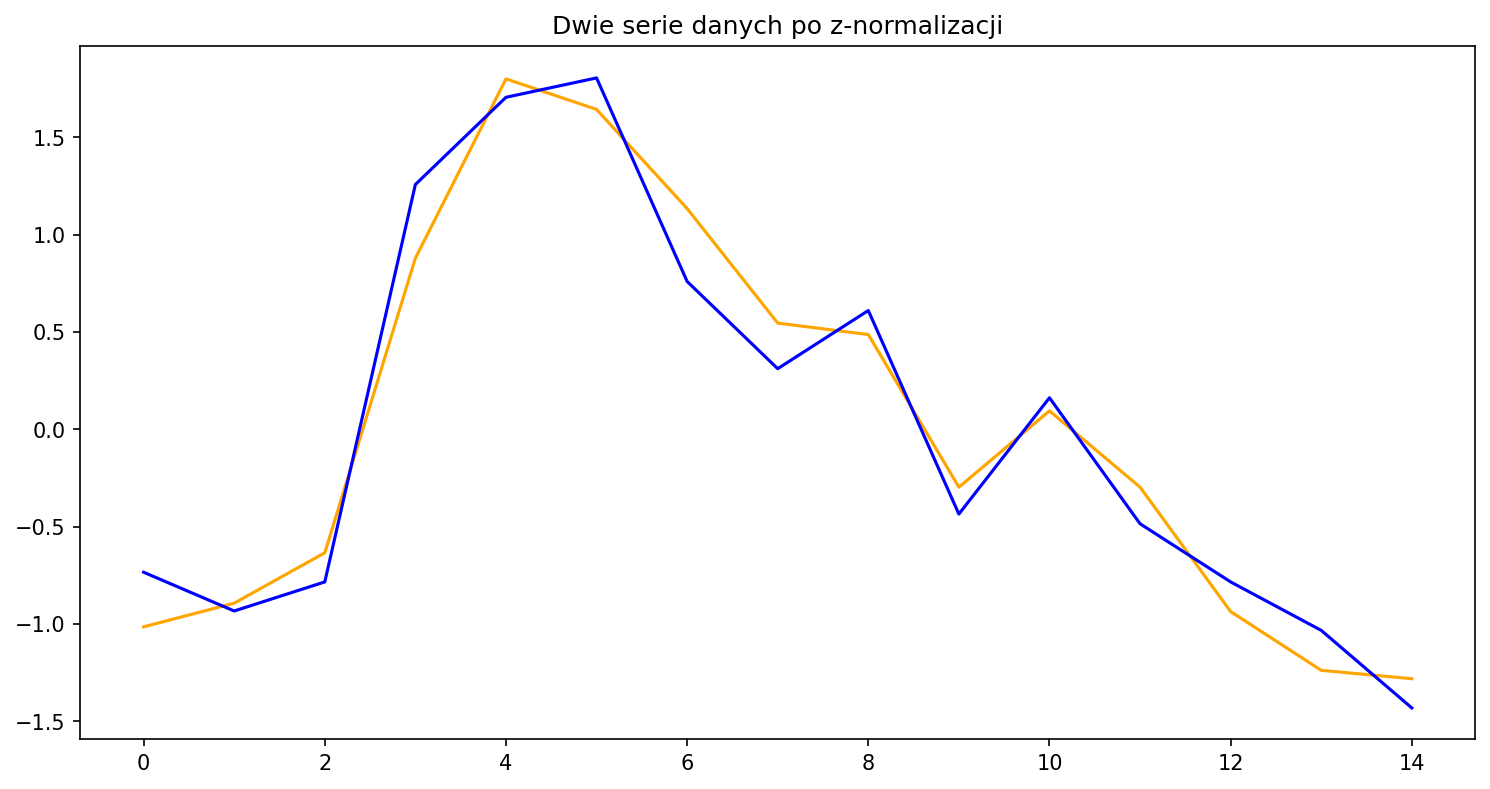

In [ ]:
# Z-normalizacja
import matplotlib.pyplot as plt
import numpy as np

s1 = np.array([2.02, 2.33, 2.99, 6.85, 9.20, 8.80, 7.50, 6.00, 5.85, 3.85, 4.85, 3.85, 2.22, 1.45, 1.34])
s2 = np.array([-0.12,-0.16,-0.13, 0.28, 0.37, 0.39, 0.18, 0.09, 0.15,-0.06, 0.06,-0.07,-0.13,-0.18,-0.26])

# z-Normalizacja
# Wykres
# Twój kod....
s1_z = (s1 - s1.mean()) / s1.std()
s2_z = (s2 - s2.mean()) / s2.std()

plt.figure(figsize=(12, 6), dpi=150)

plt.plot(s1_z, color='orange')
plt.plot(s2_z, color='blue')
plt.title ("Dwie serie danych po z-normalizacji")
plt.show()

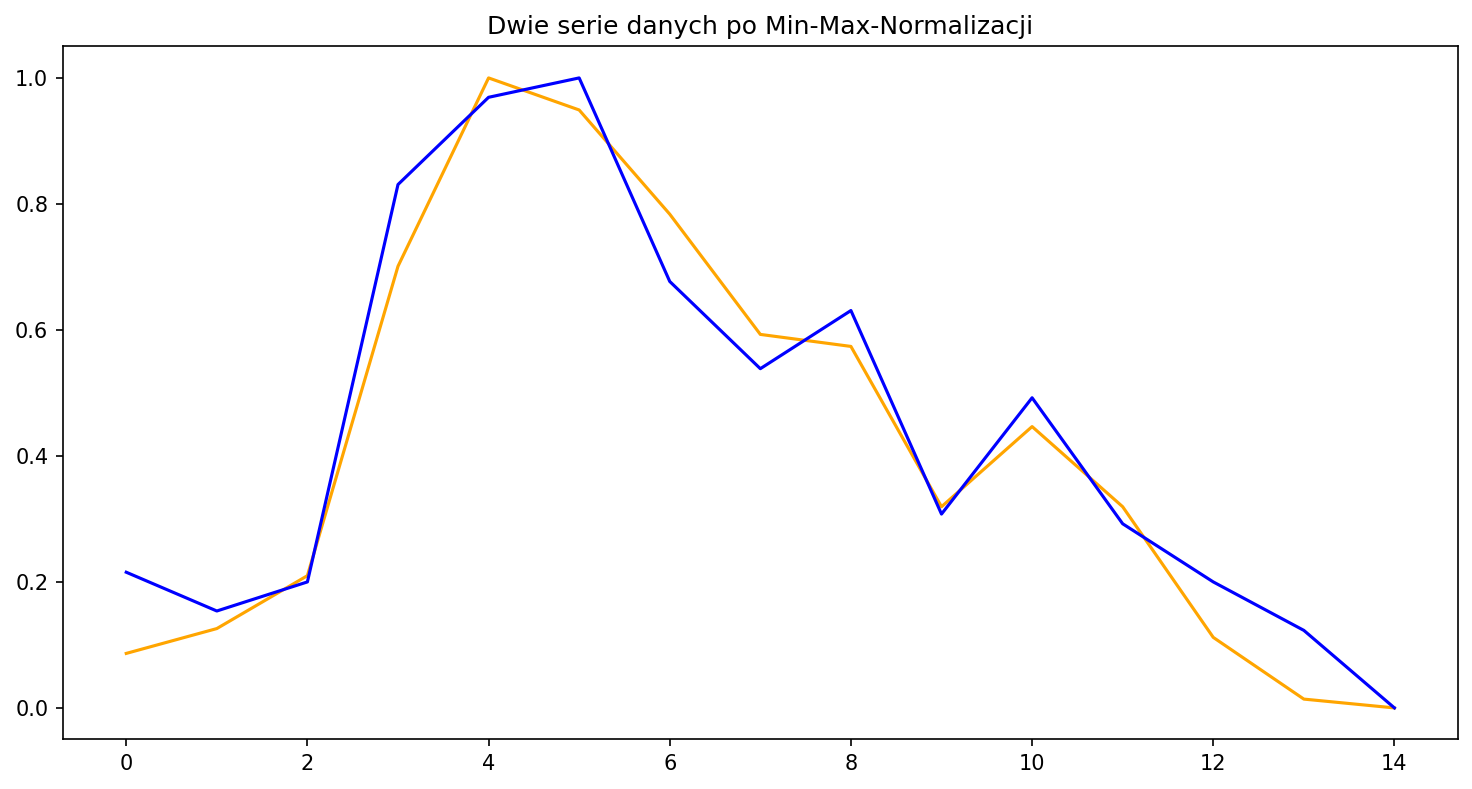

In [ ]:
#Normalizacja Min-Max
import matplotlib.pyplot as plt
import numpy as np

s1 = np.array([2.02, 2.33, 2.99, 6.85, 9.20, 8.80, 7.50, 6.00, 5.85, 3.85, 4.85, 3.85, 2.22, 1.45, 1.34])
s2 = np.array([-0.12,-0.16,-0.13, 0.28, 0.37, 0.39, 0.18, 0.09, 0.15,-0.06, 0.06,-0.07,-0.13,-0.18,-0.26])

# Min-Max-Normalizacja
# Wykres
# Twój kod....

s1_mm = (s1 - s1.min()) / (s1.max() - s1.min())
s2_mm = (s2 - s2.min()) / (s2.max() - s2.min())

plt.figure(figsize=(12, 6), dpi=150)

plt.plot(s1_mm, color='orange')
plt.plot(s2_mm, color='blue')
plt.title ("Dwie serie danych po Min-Max-Normalizacji")
plt.show()
#